In [1]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
import cftime
from dask.diagnostics import ProgressBar

In [2]:
def find_box_corners(plon, plat, lon_edge, lat_edge):
    lat_min, lat_max = plat - lat_edge / 2, plat + lat_edge / 2
    lon_min, lon_max = plon - lon_edge / 2, plon + lon_edge / 2

    # Correct longitude boundaries
    while lon_min < -180:
        lon_min += 360
    while lon_max > 180:
        lon_max -= 360
    
    if lon_max % 1.5 == 0:
        lon_max -= 0.0001
    if lat_max % 1.5 == 0:
        lat_max -= 0.0001

    return lat_min, lat_max, lon_min, lon_max

In [3]:
def flip_and_append(ds):
    # Step 2: Select Southern Hemisphere data
    ds_sh = ds.sel(lat=slice(-90,0))
    
    # Step 3: Flip the latitude values to Northern Hemisphere
    # Here, we need to change the latitude to positive values (0 to 90)
    ds_sh = ds_sh.assign_coords(lat = abs(ds_sh.lat))
    ds_sh = ds_sh.reindex(lat=list(reversed(ds_sh.lat)))
    
    date_list = []
    for date in ds_sh.time.values:
      date_list.append(cftime.Datetime360Day(date.year + ds_sh.time.values[-1].year, date.month, date.day))
    date_list = np.array(date_list)
    ds_sh = ds_sh.assign_coords(time = date_list)
    
    # Step 4: Concatenate the original dataset with the flipped Southern Hemisphere data
    # Assuming 'time' is the coordinate you want to concatenate along
    combined_ds = xr.concat([ds, ds_sh], dim='time')
    latitude = ds_sh['lat']
    ds_positive_latitudes = combined_ds.sel(lat=latitude[latitude >= 0])
    return ds_positive_latitudes

In [4]:
#ProgressBar().register()

# Path to data and experiments
base_path = '/home/links/mf671/DATA/isca_data'
experiments = [
    'exeter_project_mf_baseline_KS',
    'exeter_project_mf_aa_KS_30_72,90',
    'exeter_project_mf_baseline_st_KS',
    'exeter_project_mf_aa_st_KS_30_72,90'
]

# Load datasets
ds_clims = []

for experiment in experiments:
    ds = xr.open_dataset(f'{base_path}/{experiment}/tot/FC_1.5x1.5_2-11.nc')
    ds_clims.append(ds)


In [5]:
ds_clims[0]

<xarray.Dataset> Size: 822kB
Dimensions:    (lat: 61, lon: 240)
Coordinates:
  * lat        (lat) float64 488B 0.0 1.5 3.0 4.5 6.0 ... 85.5 87.0 88.5 90.0
  * lon        (lon) float64 2kB -180.0 -178.5 -177.0 ... 175.5 177.0 178.5
    time       object 8B ...
Data variables:
    alpha      (lat, lon) float64 117kB ...
    zgv        (lat, lon) float64 117kB ...
    qslwa      (lat, lon) float64 117kB ...
    FC         (lat, lon) float64 117kB ...
    alpha_std  (lat, lon) float64 117kB ...
    zgv_std    (lat, lon) float64 117kB ...
    FC_std     (lat, lon) float64 117kB ...

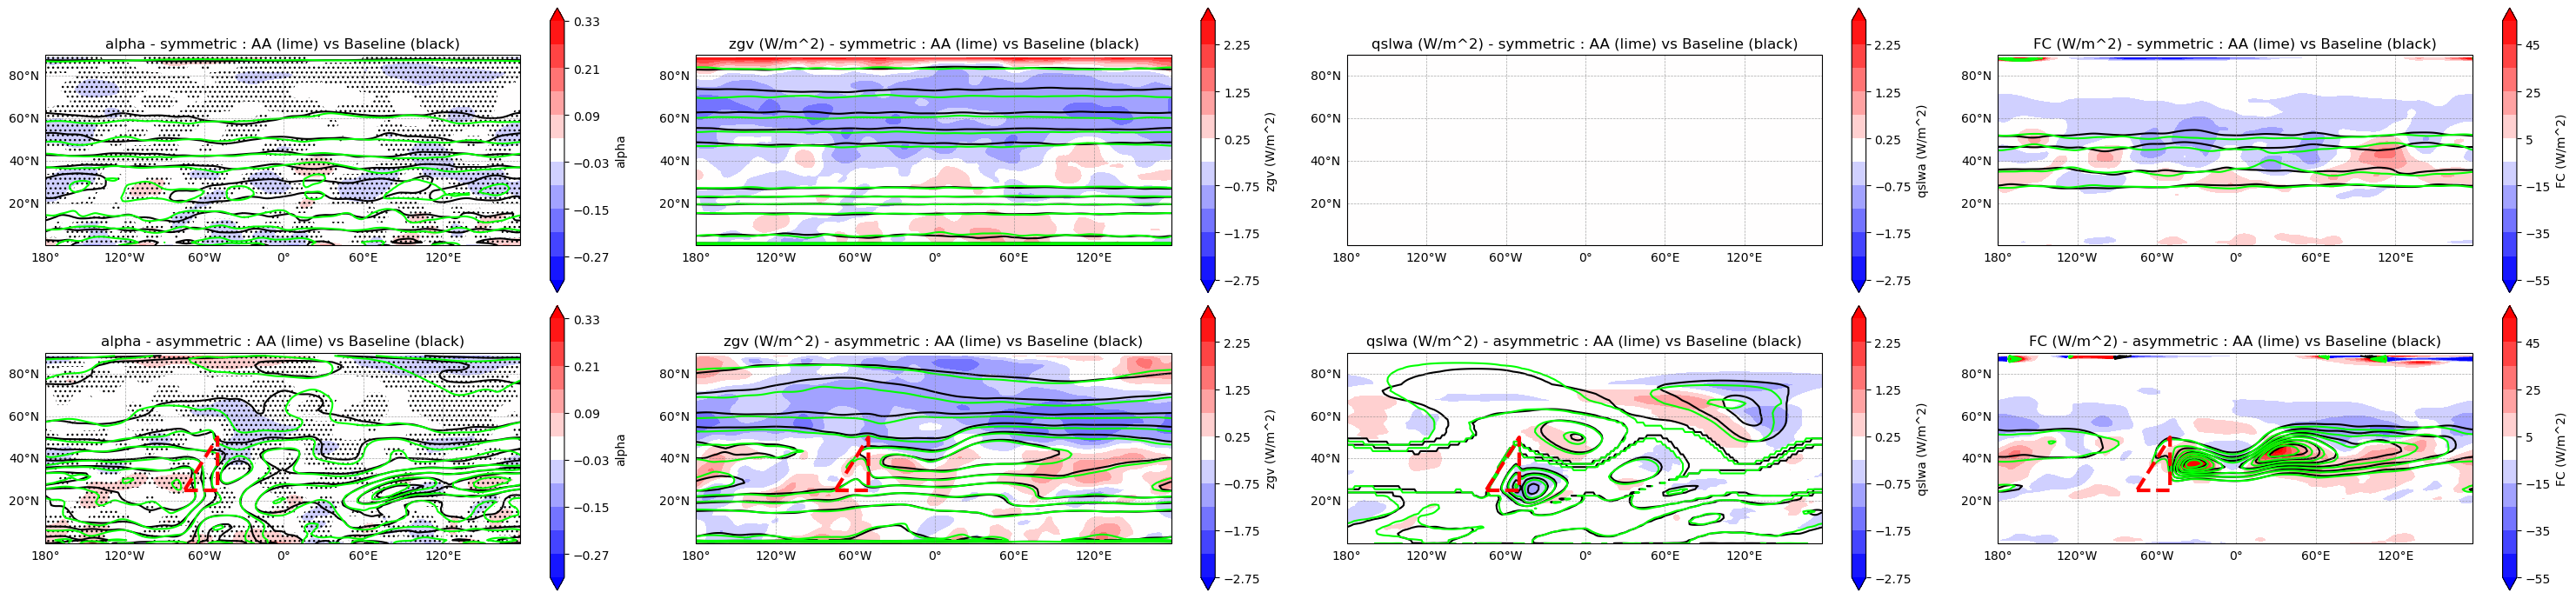

In [6]:
fig, ax = plt.subplots(2, 4, figsize=(30, 7), subplot_kw={'projection': ccrs.PlateCarree()})
ax = ax.flatten()

for axis in ax:
    axis.set_aspect(1.6)

titles = ['symmetric', 'asymmetric']
coords = [(-75.0, 25.0), (-50.0, 25.0), (-50.0, 50.0)]
lons, lats = zip(*coords)
lons += (lons[0],)
lats += (lats[0],)

for i in range(2):
    # Correct axis indexing for each block
    ax_alpha = ax[i * 4]
    ax_zgv = ax[i * 4 + 1]
    ax_qslwa = ax[i * 4 + 2]
    ax_FC = ax[i * 4 + 3]
    ds_a = ds_clims[i * 2]
    ds_b = ds_clims[i * 2 + 1]

    # alpha plot
    levels = np.arange(0, 1, 0.1)
    levels_diff = np.arange(-0.22, 0.23, 0.04)*1.5
    ax_alpha.set_title(f'alpha - {titles[i]} : AA (lime) vs Baseline (black)')
    ax_alpha.contour(ds_a['lon'], ds_a['lat'], ds_a['alpha'], levels=levels, colors='black', transform=ccrs.PlateCarree())
    ax_alpha.contour(ds_b['lon'], ds_b['lat'], ds_b['alpha'], levels=levels, colors='lime', transform=ccrs.PlateCarree())
    sh = ax_alpha.contourf(ds_a['lon'], ds_a['lat'], ds_b['alpha'] - ds_a['alpha'], levels=levels_diff, cmap='bwr', alpha=1, extend='both', transform=ccrs.PlateCarree())
    fig.colorbar(sh, ax=ax_alpha, orientation='vertical', label='alpha')
    if i > 0:
        ax_alpha.plot(lons, lats, linestyle='--', linewidth=3, color='red', transform=ccrs.PlateCarree())
    significance = np.abs(ds_b['alpha'] - ds_a['alpha']) > np.sqrt(ds_a['alpha_std']**2 + ds_b['alpha_std']**2)
    ax_alpha.contourf(ds_a['lon'], ds_a['lat'], significance, levels=[0.5, 1], hatches=['...', None], colors='none', transform=ccrs.PlateCarree())
    gl_alpha = ax_alpha.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
    gl_alpha.top_labels = False
    gl_alpha.right_labels = False

    # zgv plot
    levels = np.arange(0, 40, 4)
    levels_diff = np.arange(-11, 12, 2)/4
    ax_zgv.set_title(f'zgv (W/m^2) - {titles[i]} : AA (lime) vs Baseline (black)')
    ax_zgv.contour(ds_a['lon'], ds_a['lat'], ds_a['zgv'], levels=levels, colors='black', transform=ccrs.PlateCarree())
    ax_zgv.contour(ds_b['lon'], ds_b['lat'], ds_b['zgv'], levels=levels, colors='lime', transform=ccrs.PlateCarree())
    sh2 = ax_zgv.contourf(ds_a['lon'], ds_a['lat'], ds_b['zgv'] - ds_a['zgv'], levels=levels_diff, cmap='bwr', alpha=1, extend='both', transform=ccrs.PlateCarree())
    fig.colorbar(sh2, ax=ax_zgv, orientation='vertical', label='zgv (W/m^2)')
    if i > 0:
        ax_zgv.plot(lons, lats, linestyle='--', linewidth=3, color='red', transform=ccrs.PlateCarree())
    significance2 = np.abs(ds_b['zgv'] - ds_a['zgv']) > np.sqrt(ds_a['zgv_std']**2 + ds_b['zgv_std']**2)
    #ax_zgv.contourf(ds_a['lon'], ds_a['lat'], significance2, levels=[0.5, 1], hatches=['...', None], colors='none', transform=ccrs.PlateCarree())
    gl_zgv = ax_zgv.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
    gl_zgv.top_labels = False
    gl_zgv.right_labels = False

    # qslwa plot
    levels = np.arange(0, 20, 2)
    levels_diff = np.arange(-5.5, 6, 1)/2
    ax_qslwa.set_title(f'qslwa (W/m^2) - {titles[i]} : AA (lime) vs Baseline (black)')
    ax_qslwa.contour(ds_a['lon'], ds_a['lat'], ds_a['qslwa'], levels=levels, colors='black', transform=ccrs.PlateCarree())
    ax_qslwa.contour(ds_b['lon'], ds_b['lat'], ds_b['qslwa'], levels=levels, colors='lime', transform=ccrs.PlateCarree())
    sh3 = ax_qslwa.contourf(ds_a['lon'], ds_a['lat'], ds_b['qslwa'] - ds_a['qslwa'], levels=levels_diff, cmap='bwr', alpha=1, extend='both', transform=ccrs.PlateCarree())
    fig.colorbar(sh3, ax=ax_qslwa, orientation='vertical', label='qslwa (W/m^2)')
    if i > 0:
        ax_qslwa.plot(lons, lats, linestyle='--', linewidth=3, color='red', transform=ccrs.PlateCarree())
    #significance3 = np.abs(ds_b['qslwa'] - ds_a['qslwa']) > np.sqrt(ds_a['qslwa_std']**2 + ds_b['qslwa_std']**2)
    #ax_qslwa.contourf(ds_a['lon'], ds_a['lat'], significance3, levels=[0.5, 1], hatches=['...', None], colors='none', transform=ccrs.PlateCarree())
    gl_qslwa = ax_qslwa.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
    gl_qslwa.top_labels = False
    gl_qslwa.right_labels = False

    # FC plot
    levels = np.arange(100, 400, 40)
    levels_diff = np.arange(-55, 60, 10)
    ax_FC.set_title(f'FC (W/m^2) - {titles[i]} : AA (lime) vs Baseline (black)')
    ax_FC.contour(ds_a['lon'], ds_a['lat'], ds_a['FC'], levels=levels, colors='black', transform=ccrs.PlateCarree())
    ax_FC.contour(ds_b['lon'], ds_b['lat'], ds_b['FC'], levels=levels, colors='lime', transform=ccrs.PlateCarree())
    sh4 = ax_FC.contourf(ds_a['lon'], ds_a['lat'], ds_b['FC'] - ds_a['FC'], levels=levels_diff, cmap='bwr', alpha=1, extend='both', transform=ccrs.PlateCarree())
    fig.colorbar(sh4, ax=ax_FC, orientation='vertical', label='FC (W/m^2)')
    if i > 0:
        ax_FC.plot(lons, lats, linestyle='--', linewidth=3, color='red', transform=ccrs.PlateCarree())
    significance4 = np.abs(ds_b['FC'] - ds_a['FC']) > np.sqrt(ds_a['FC_std']**2 + ds_b['FC_std']**2)
    #ax_FC.contourf(ds_a['lon'], ds_a['lat'], significance4, levels=[0.5, 1], hatches=['...', None], colors='none', transform=ccrs.PlateCarree())
    gl_FC = ax_FC.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
    gl_FC.top_labels = False
    gl_FC.right_labels = False

plt.tight_layout()

/tmp/ipykernel_169720/517438410.py:46: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax_diff.set_ylim(-max_abs, max_abs)


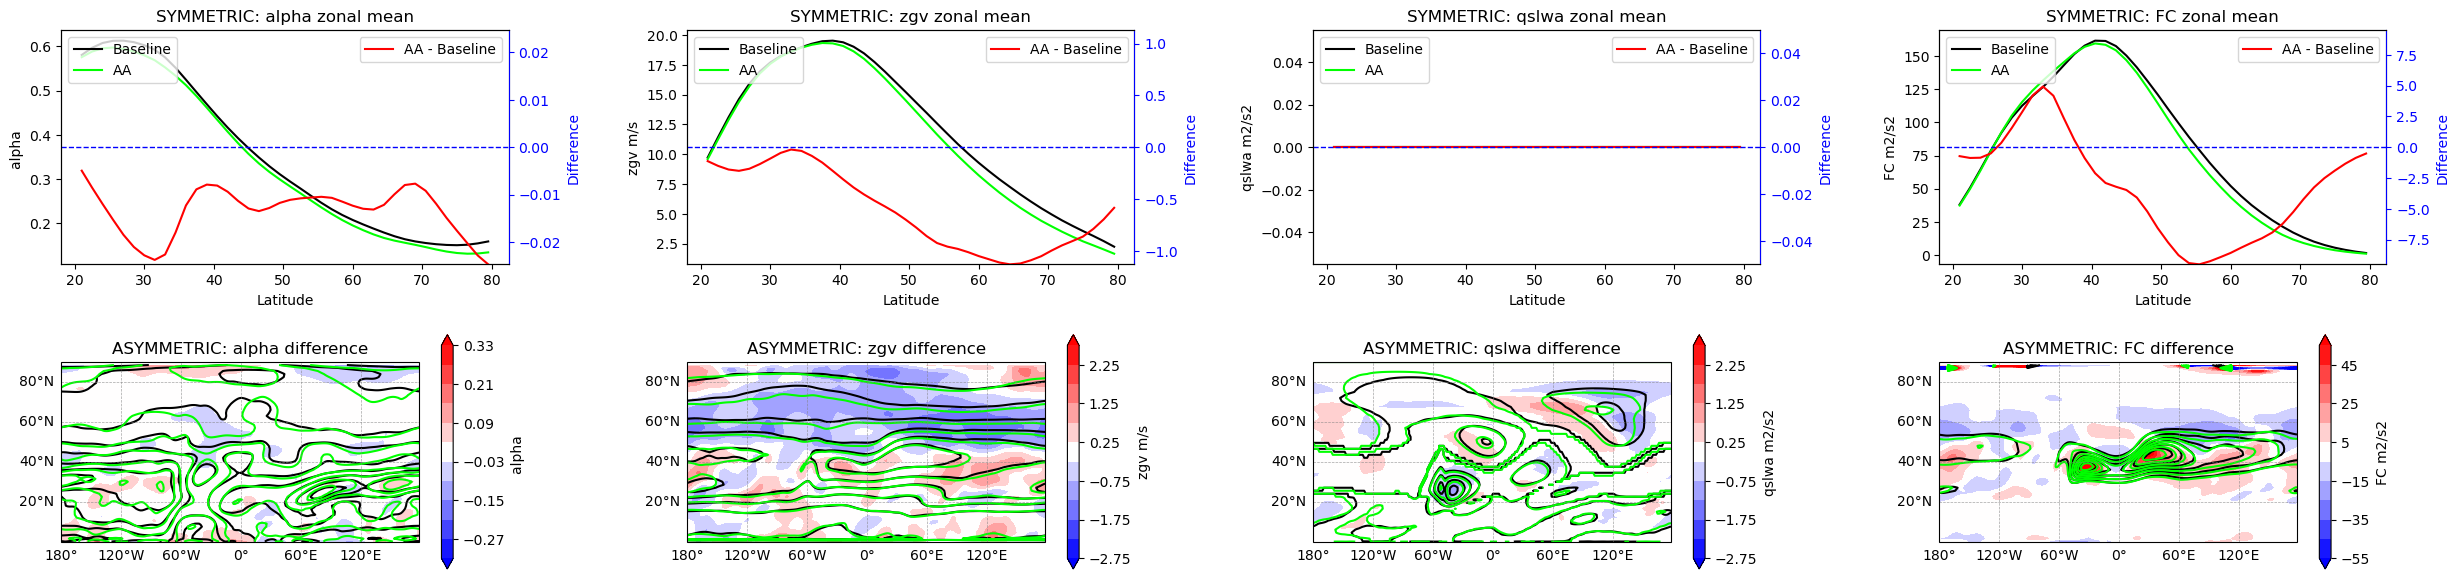

In [7]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(30, 7))
gs = gridspec.GridSpec(2, 4, figure=fig, wspace=0.4, hspace=0.3)

# First row: 1D plots
ax1 = [fig.add_subplot(gs[0, i]) for i in range(4)]

# Second row: GeoAxes for 2D contour plots
ax2 = [fig.add_subplot(gs[1, i], projection=ccrs.PlateCarree()) for i in range(4)]
for axis in ax2:
    axis.set_aspect(2)

titles = ['alpha', 'zgv', 'qslwa', 'FC']
units = ['', 'm/s', 'm2/s2', 'm2/s2']

# 1D zonal mean plots
for i, field in enumerate(['alpha', 'zgv', 'qslwa', 'FC']):
    lat = ds_clims[0]['lat']
    mean_a = ds_clims[0][field].mean(dim='lon')
    mean_b = ds_clims[1][field].mean(dim='lon')
    diff = mean_b - mean_a

    mask = (lat >= 20) & (lat <= 80)
    lat_filt = lat[mask]
    mean_a_filt = mean_a[mask]
    mean_b_filt = mean_b[mask]
    diff_filt = diff[mask]

    ax1[i].plot(lat_filt, mean_a_filt, color='black', label='Baseline')
    ax1[i].plot(lat_filt, mean_b_filt, color='lime', label='AA')
    ax1[i].set_title(f'SYMMETRIC: {titles[i]} zonal mean')
    ax1[i].set_xlabel('Latitude')
    ax1[i].set_ylabel(f'{titles[i]} {units[i]}')
    ax1[i].legend(loc='upper left')

    ax_diff = ax1[i].twinx()
    ax_diff.plot(lat_filt, diff_filt, color='red', label='AA - Baseline')
    ax_diff.set_ylabel('Difference', color='blue')
    ax_diff.tick_params(axis='y', colors='blue')
    ax_diff.spines['right'].set_color('blue')
    ax_diff.legend(loc='upper right')
    max_abs = np.max(np.abs(diff_filt))
    ax_diff.set_ylim(-max_abs, max_abs)
    ax_diff.axhline(0, color='blue', linestyle='--', linewidth=1)

levels = [
    np.arange(0, 1, 0.1),
    np.arange(0, 40, 4),
    np.arange(0, 20, 2),
    np.arange(100, 400, 40)
]
levels_diff = [
    np.arange(-0.22, 0.23, 0.04)*1.5,
    np.arange(-11, 12, 2)/4,
    np.arange(-5.5, 6, 1)/2,
    np.arange(-55, 60, 10)    
]

# 2D contour plots
for i, field in enumerate(['alpha', 'zgv', 'qslwa', 'FC']):
    ds_a = ds_clims[2]
    ds_b = ds_clims[3]
    diff_field = ds_b[field] - ds_a[field]
    ax2[i].set_title(f'ASYMMETRIC: {titles[i]} difference')
    ax2[i].contour(ds_a['lon'], ds_a['lat'], ds_a[field], levels=levels[i], colors='black', transform=ccrs.PlateCarree())
    ax2[i].contour(ds_b['lon'], ds_b['lat'], ds_b[field], levels=levels[i], colors='lime', transform=ccrs.PlateCarree())
    sh = ax2[i].contourf(ds_a['lon'], ds_a['lat'], diff_field, levels=levels_diff[i], cmap='bwr', alpha=1, extend='both', transform=ccrs.PlateCarree())
    fig.colorbar(sh, ax=ax2[i], orientation='vertical', label=f'{titles[i]} {units[i]}')
    gl = ax2[i].gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False


/tmp/ipykernel_169720/2518644515.py:35: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax_diff.set_ylim(-max_abs, max_abs)


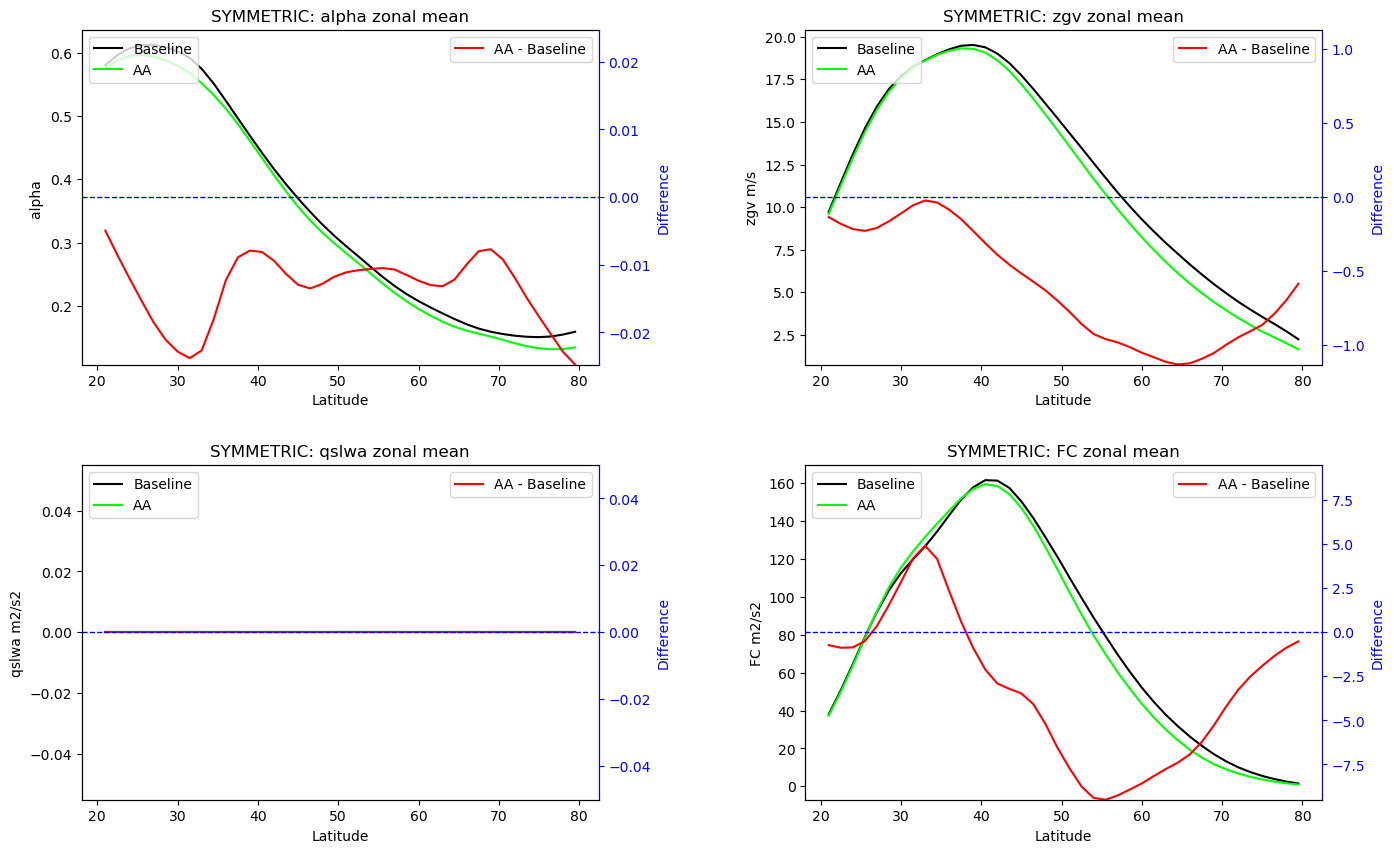

In [9]:
fig1 = plt.figure(figsize=(16, 10))
gs1 = gridspec.GridSpec(2, 2, figure=fig1, wspace=0.4, hspace=0.3)
ax1 = [fig1.add_subplot(gs1[i // 2, i % 2]) for i in range(4)]

titles = ['alpha', 'zgv', 'qslwa', 'FC']
units = ['', 'm/s', 'm2/s2', 'm2/s2']

# 1D zonal mean plots (fig1)
for i, field in enumerate(['alpha', 'zgv', 'qslwa', 'FC']):
    lat = ds_clims[0]['lat']
    mean_a = ds_clims[0][field].mean(dim='lon')
    mean_b = ds_clims[1][field].mean(dim='lon')
    diff = mean_b - mean_a

    mask = (lat >= 20) & (lat <= 80)
    lat_filt = lat[mask]
    mean_a_filt = mean_a[mask]
    mean_b_filt = mean_b[mask]
    diff_filt = diff[mask]

    ax1[i].plot(lat_filt, mean_a_filt, color='black', label='Baseline')
    ax1[i].plot(lat_filt, mean_b_filt, color='lime', label='AA')
    ax1[i].set_title(f'SYMMETRIC: {titles[i]} zonal mean')
    ax1[i].set_xlabel('Latitude')
    ax1[i].set_ylabel(f'{titles[i]} {units[i]}')
    ax1[i].legend(loc='upper left')

    ax_diff = ax1[i].twinx()
    ax_diff.plot(lat_filt, diff_filt, color='red', label='AA - Baseline')
    ax_diff.set_ylabel('Difference', color='blue')
    ax_diff.tick_params(axis='y', colors='blue')
    ax_diff.spines['right'].set_color('blue')
    ax_diff.legend(loc='upper right')
    max_abs = np.max(np.abs(diff_filt))
    ax_diff.set_ylim(-max_abs, max_abs)
    ax_diff.axhline(0, color='blue', linestyle='--', linewidth=1)


/tmp/ipykernel_169720/1614007433.py:35: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


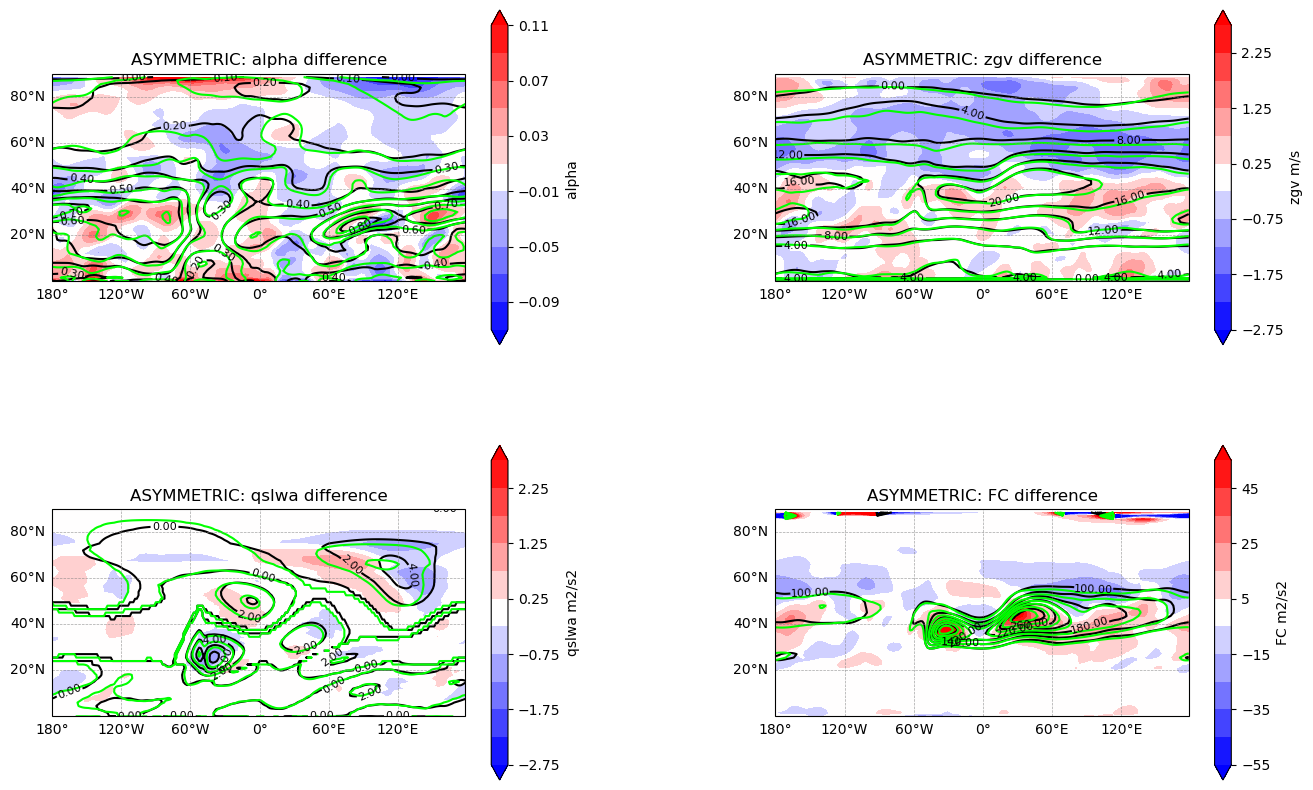

In [13]:
fig2 = plt.figure(figsize=(16, 10))
gs2 = gridspec.GridSpec(2, 2, figure=fig2, wspace=0.4, hspace=0.3)
ax2 = [fig2.add_subplot(gs2[i // 2, i % 2], projection=ccrs.PlateCarree()) for i in range(4)]
for axis in ax2:
    axis.set_aspect(2)
    
levels = [
    np.arange(0, 1, 0.1),
    np.arange(0, 40, 4),
    np.arange(0, 20, 2),
    np.arange(100, 400, 40)
]
levels_diff = [
    np.arange(-0.22, 0.23, 0.04)/2,
    np.arange(-11, 12, 2)/4,
    np.arange(-5.5, 6, 1)/2,
    np.arange(-55, 60, 10)    
]

# 2D contour plots (fig2)
for i, field in enumerate(['alpha', 'zgv', 'qslwa', 'FC']):
    ds_a = ds_clims[2]
    ds_b = ds_clims[3]
    diff_field = ds_b[field] - ds_a[field]
    ax2[i].set_title(f'ASYMMETRIC: {titles[i]} difference')
    cs = ax2[i].contour(ds_a['lon'], ds_a['lat'], ds_a[field], levels=levels[i], colors='black', transform=ccrs.PlateCarree())
    ax2[i].clabel(cs, fmt='%1.2f', fontsize=8)
    ax2[i].contour(ds_b['lon'], ds_b['lat'], ds_b[field], levels=levels[i], colors='lime', transform=ccrs.PlateCarree())
    sh = ax2[i].contourf(ds_a['lon'], ds_a['lat'], diff_field, levels=levels_diff[i], cmap='bwr', alpha=1, extend='both', transform=ccrs.PlateCarree())
    fig2.colorbar(sh, ax=ax2[i], orientation='vertical', label=f'{titles[i]} {units[i]}')
    gl = ax2[i].gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False

plt.tight_layout()